# House Prices: Decision Tree, Random Forest, Gradient Boosting

## 1. Loading and preparing the dataset

In [34]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [35]:
df = pd.read_csv('house-prices-advanced-regression-techniques/train.csv')

TARGET = 'SalePrice'
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Exploratory data analysis

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [37]:
missing = df.isna().sum()[lambda s: s > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({
    'n_missing': missing,
    'pct_missing': missing_pct,
})
missing_table

,n_missing,pct_missing
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


Skewness: 1.883
Kurtosis: 6.536


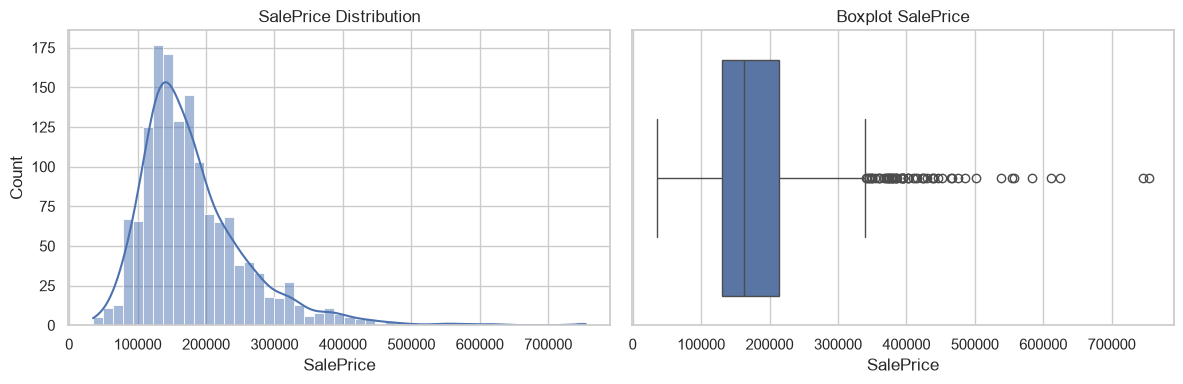

In [38]:
display(df['SalePrice'].describe().to_frame())
print(f"Skewness: {df['SalePrice'].skew():.3f}")
print(f"Kurtosis: {df['SalePrice'].kurtosis():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0])
axes[0].set_title(f'{TARGET} Distribution')
sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title(f'Boxplot {TARGET}')
plt.tight_layout()
plt.show()

### Feature matrix X and target vector y

In [39]:
X = df.drop(columns=[TARGET, 'Id']).copy()
y = df[TARGET].copy()

In [40]:
X['MSSubClass'] = X['MSSubClass'].astype(str)

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include=[str]).columns.tolist()

## 3. Splitting into train, validation, and test sets

In [41]:
price_bins_strat = pd.qcut(y, q=5, duplicates='drop')

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_bins_strat)

strat_trainval = pd.qcut(y_trainval, q=5, duplicates='drop')
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE, stratify=strat_trainval)

print(f"X_train: {X_train.shape} ({len(X_train)/len(X):.0%})")
print(f"X_val:   {X_val.shape} ({len(X_val)/len(X):.0%})")
print(f"X_test:  {X_test.shape} ({len(X_test)/len(X):.0%})")

X_train: (876, 79) (60%)
X_val:   (292, 79) (20%)
X_test:  (292, 79) (20%)


### Handling missing values, encoding, and feature scaling

In [42]:
none_means_absence = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu', 
       'GarageType', 'GarageCond', 'GarageFinish', 'GarageQual', 'BsmtFinType2', 
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1']


def build_preprocessor(X_fit_raw):
    Xf = X_fit_raw.copy()
    for col in none_means_absence:
       Xf[col] = Xf[col].fillna('None')
    
    cat_cols = Xf.select_dtypes(include=[str]).columns.tolist()
    num_cols = Xf.select_dtypes(include=[np.number]).columns.tolist()

    remaining_cat = [c for c in cat_cols if Xf[c].isna().any()]
    remaining_num = [c for c in num_cols if Xf[c].isna().any()]

    cat_imputer = SimpleImputer(strategy='most_frequent')
    if remaining_cat:
        cat_imputer.fit(Xf[remaining_cat])
        Xf[remaining_cat] = cat_imputer.transform(Xf[remaining_cat])

    num_imputer = SimpleImputer(strategy='median')
    if remaining_num:
        num_imputer.fit(Xf[remaining_num])
        Xf[remaining_num] = num_imputer.transform(Xf[remaining_num])

    iqr_bounds = {}
    for c in num_cols:
        q1, q3 = Xf[c].quantile(0.25), Xf[c].quantile(0.75)
        iqr = q3 - q1
        iqr_bounds[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
        Xf[c] = Xf[c].clip(lower=iqr_bounds[c][0], upper=iqr_bounds[c][1])

        ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        ohe.fit(Xf[cat_cols])

        # scaler = StandardScaler()
        # scaler.fit(Xf[num_cols])


    return dict(cat_cols=cat_cols, num_cols=num_cols, 
                remaining_cat=remaining_cat, remaining_num=remaining_num, 
                cat_imputer=cat_imputer, num_imputer=num_imputer,
                iqr_bounds=iqr_bounds, ohe=ohe)


def apply_preprocessor(X_raw, prep):
    Xr = X_raw.copy()
    for col in none_means_absence:
        Xr[col] = Xr[col].fillna('None')

    if prep['remaining_cat']:
        Xr[prep['remaining_cat']] = prep['cat_imputer'].transform(Xr[prep['remaining_cat']])
    if prep['remaining_num']:
        Xr[prep['remaining_num']] = prep['num_imputer'].transform(Xr[prep['remaining_num']])

    for c in prep['num_cols']:
        lo, hi = prep['iqr_bounds'][c]
        Xr[c] = Xr[c].clip(lower=lo, upper=hi)

    X_cat = pd.DataFrame(
        prep['ohe'].transform(Xr[prep['cat_cols']]),
        columns=prep['ohe'].get_feature_names_out(prep['cat_cols']),
        index=Xr.index
    )
    X_num = Xr[prep['num_cols']].reset_index(drop=True)
    X_num.index = Xr.index
    
    return pd.concat([X_num, X_cat], axis=1)

In [43]:
prep = build_preprocessor(X_train)

X_train_final = apply_preprocessor(X_train, prep).reset_index(drop=True)
X_val_final = apply_preprocessor(X_val, prep).reset_index(drop=True)
X_test_final = apply_preprocessor(X_test, prep).reset_index(drop=True)

y_train_final = y_train.reset_index(drop=True)
y_val_final = y_val.reset_index(drop=True)
y_test_final = y_test.reset_index(drop=True)

print(f"X_train_final: {X_train_final.shape}")
print(f"X_val_final:   {X_val_final.shape}")
print(f"X_test_final:  {X_test_final.shape}")

X_train_final: (876, 304)
X_val_final:   (292, 304)
X_test_final:  (292, 304)


In [44]:
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

## 4–6. Decision Tree

In [45]:
dt_base = DecisionTreeRegressor(random_state=RANDOM_STATE)
dt_base.fit(X_train_final, y_train_final)

dt_base_train_metrics = regression_metrics(y_train_final, dt_base.predict(X_train_final))
dt_base_val_metrics = regression_metrics(y_val_final, dt_base.predict(X_val_final))

print(f"Depth of the unregularized tree: {dt_base.get_depth()}, leaves: {dt_base.get_n_leaves()}")
pd.DataFrame({'train': dt_base_train_metrics, 'validation': dt_base_val_metrics}).T

Depth of the unregularized tree: 22, leaves: 843


,MAE,MSE,RMSE,R2
train,0.000000,0.000000e+00,0.000000,1.000000
validation,27575.140411,1.653584e+09,40664.288471,0.732627


### 5. The effect of max_depth, min_samples_split, min_samples_leaf

In [46]:
max_depth_values = [2, 3, 4, 5, 6, 8, 10, 15, 20, None]

dt_depth_results = []
dt_depth_models = {}
for depth in max_depth_values:
    model = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train_final, y_train_final)
    dt_depth_models[depth] = model
    train_m = regression_metrics(y_train_final, model.predict(X_train_final))
    val_m = regression_metrics(y_val_final, model.predict(X_val_final))
    dt_depth_results.append({
        'max_depth': depth if depth is not None else 'None',
        'RMSE_train': train_m['RMSE'], 'RMSE_val': val_m['RMSE'],
        'R2_train': train_m['R2'], 'R2_val': val_m['R2'],
    })

dt_depth_df = pd.DataFrame(dt_depth_results)
dt_depth_df

,max_depth,RMSE_train,RMSE_val,R2_train,R2_val
0,2,49145.285959,50357.988714,0.652225,0.589958
1,3,40821.055432,44104.761195,0.760059,0.685470
2,4,34730.826607,38959.788275,0.826314,0.754572
3,5,29539.771377,39384.323745,0.874354,0.749194
4,6,24027.498490,39385.284268,0.916871,0.749182
5,8,14077.409468,37034.007910,0.971465,0.778235
6,10,7446.086434,39777.812386,0.992017,0.744157
7,15,823.371358,40051.100029,0.999902,0.740630
8,20,14.804664,39703.316326,1.000000,0.745115
9,None,0.000000,40664.288471,1.000000,0.732627


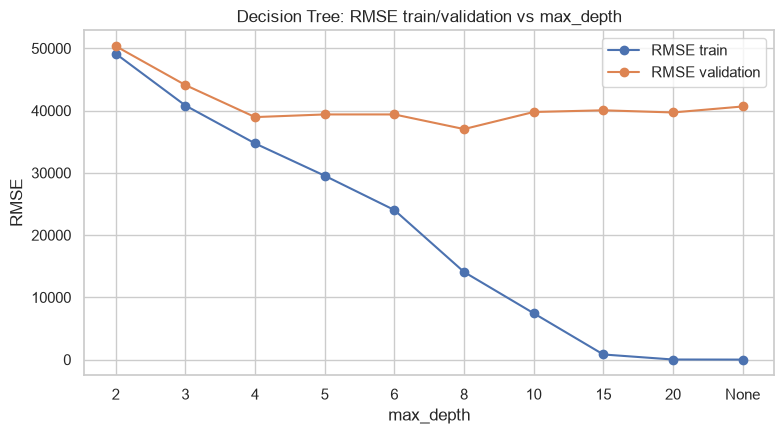

In [47]:
plt.figure(figsize=(8, 4.5))
x_plot = range(len(dt_depth_df))
plt.plot(x_plot, dt_depth_df['RMSE_train'], marker='o', label='RMSE train')
plt.plot(x_plot, dt_depth_df['RMSE_val'], marker='o', label='RMSE validation')
plt.xticks(x_plot, dt_depth_df['max_depth'])
plt.xlabel('max_depth')
plt.ylabel('RMSE')
plt.title('Decision Tree: RMSE train/validation vs max_depth')
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
best_depth_idx = dt_depth_df['RMSE_val'].idxmin()
best_max_depth = dt_depth_df.loc[best_depth_idx, 'max_depth']
best_max_depth = None if best_max_depth == 'None' else int(best_max_depth)
print(f"Best max_depth (min RMSE(val)): {best_max_depth}")

Best max_depth (min RMSE(val)): 8


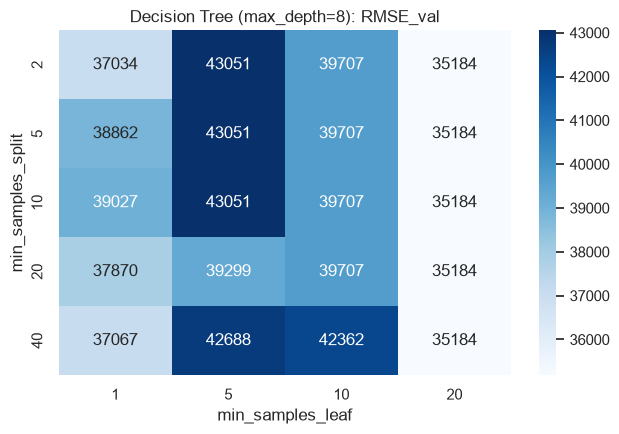

Best values: min_samples_split=2, min_samples_leaf=20 (RMSE_val=35183.65)


In [49]:
min_samples_split_values = [2, 5, 10, 20, 40]
min_samples_leaf_values = [1, 5, 10, 20]

mss_msl_results = []
for mss in min_samples_split_values:
    for msl in min_samples_leaf_values:
        model = DecisionTreeRegressor(max_depth=best_max_depth, min_samples_split=mss,
                                      min_samples_leaf=msl, random_state=RANDOM_STATE)
        model.fit(X_train_final, y_train_final)
        val_m = regression_metrics(y_val_final, model.predict(X_val_final))
        mss_msl_results.append({'min_samples_split': mss, 'min_samples_leaf': msl,
                                'RMSE_val': val_m['RMSE'], 'R2_val': val_m['R2']})

mss_msl_df = pd.DataFrame(mss_msl_results)
pivot_mss_msl = mss_msl_df.pivot(index='min_samples_split', columns='min_samples_leaf', values='RMSE_val')

plt.figure(figsize=(6.5, 4.5))
sns.heatmap(pivot_mss_msl, annot=True, fmt='.0f', cmap='Blues')
plt.title(f'Decision Tree (max_depth={best_max_depth}): RMSE_val')
plt.tight_layout()
plt.show()

best_row = mss_msl_df.loc[mss_msl_df['RMSE_val'].idxmin()]
best_min_samples_split = int(best_row['min_samples_split'])
best_min_samples_leaf = int(best_row['min_samples_leaf'])
print(f"Best values: min_samples_split={best_min_samples_split}, min_samples_leaf={best_min_samples_leaf} (RMSE_val={best_row['RMSE_val']:.2f})")

In [50]:
dt_best = DecisionTreeRegressor(max_depth=best_max_depth, min_samples_split=best_min_samples_split,
                                min_samples_leaf=best_min_samples_leaf, random_state=RANDOM_STATE)

dt_best.fit(X_train_final, y_train_final)
dt_val_pred = dt_best.predict(X_val_final)

dt_train_metrics = regression_metrics(y_train_final, dt_best.predict(X_train_final))
dt_val_metrics = regression_metrics(y_val_final, dt_val_pred)

print(f"Selected Decision Tree config: max_depth={best_max_depth}, min_samples_split={best_min_samples_split}, min_samples_leaf={best_min_samples_leaf}")
pd.DataFrame({'train': dt_train_metrics, 'validation': dt_val_metrics}).T

Selected Decision Tree config: max_depth=8, min_samples_split=2, min_samples_leaf=20


,MAE,MSE,RMSE,R2
train,22316.522616,1.323321e+09,36377.485510,0.809454
validation,25251.768475,1.237889e+09,35183.648833,0.799842


## 6. Analysis of Decision Tree overfitting

In [51]:
dt_overfit_table = pd.DataFrame({
    'Unregularized tree': {**dt_base_train_metrics, **{f'{k}_val': v for k, v in dt_base_val_metrics.items()}},
}).T

overfit_compare = pd.DataFrame({
    'R2_train': [dt_base_train_metrics['R2'], dt_train_metrics['R2']],
    'R2_val': [dt_base_val_metrics['R2'], dt_val_metrics['R2']],
    'RMSE_train': [dt_base_train_metrics['RMSE'], dt_train_metrics['RMSE']],
    'RMSE_val': [dt_base_val_metrics['RMSE'], dt_val_metrics['RMSE']],
}, index=['Unregularized (max_depth=None)', f'Regularized (max_depth={best_max_depth})'])
overfit_compare['gap_R2'] = overfit_compare['R2_train'] - overfit_compare['R2_val']
overfit_compare

,R2_train,R2_val,RMSE_train,RMSE_val,gap_R2
Unregularized (max_depth=None),1.000000,0.732627,0.00000,40664.288471,0.267373
Regularized (max_depth=8),0.809454,0.799842,36377.48551,35183.648833,0.009612


## 7. Random Forest

In [52]:
rf_base = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train_final, y_train_final)

rf_base_train_metrics = regression_metrics(y_train_final, rf_base.predict(X_train_final))
rf_base_val_metrics = regression_metrics(y_val_final, rf_base.predict(X_val_final))

print("Random Forest (base config, n_estimators=200) metrics:")
pd.DataFrame({'train': rf_base_train_metrics, 'validation': rf_base_val_metrics}).T

Random Forest (base config, n_estimators=200) metrics:


,MAE,MSE,RMSE,R2
train,6708.040816,1.302331e+08,11411.973062,0.981248
validation,17904.733151,7.042638e+08,26537.968108,0.886126


## 8. The effect of n_estimators, max_depth, max_features

In [54]:
n_estimators_values = [10, 25, 50, 100, 200, 300, 500]

rf_nest_results = []
for n in n_estimators_values:
    model = RandomForestRegressor(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_train_final, y_train_final)
    train_m = regression_metrics(y_train_final, model.predict(X_train_final))
    val_m = regression_metrics(y_val_final, model.predict(X_val_final))
    rf_nest_results.append({'n_estimators': n, 'RMSE_train': train_m['RMSE'],
                            'RMSE_val': val_m['RMSE'], 'R2_val': val_m['R2']})

rf_nest_df = pd.DataFrame(rf_nest_results)
rf_nest_df

,n_estimators,RMSE_train,RMSE_val,R2_val
0,10,12800.022635,28490.210680,0.868755
1,25,12317.093587,27708.211926,0.875861
2,50,11736.576192,27441.302810,0.878241
3,100,11518.472325,27150.296342,0.880810
4,200,11411.973062,26537.968108,0.886126
5,300,11552.493414,26590.431175,0.885675
6,500,11668.922886,26583.748844,0.885732


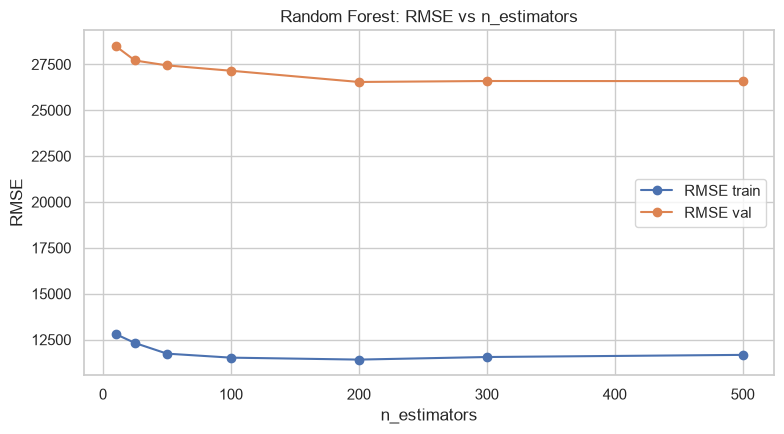

Best n_estimators (min RMSE(val)): 200


In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(rf_nest_df['n_estimators'], rf_nest_df['RMSE_train'], marker='o', label='RMSE train')
plt.plot(rf_nest_df['n_estimators'], rf_nest_df['RMSE_val'], marker='o', label='RMSE val')
plt.xlabel('n_estimators')
plt.ylabel('RMSE')
plt.title('Random Forest: RMSE vs n_estimators')
plt.legend()
plt.tight_layout()
plt.show()

best_n_estimators = int(rf_nest_df.loc[rf_nest_df['RMSE_val'].idxmin(), 'n_estimators'])
print(f"Best n_estimators (min RMSE(val)): {best_n_estimators}")

In [65]:
max_depth_values_rf = [5, 10, 15, 20, 30, None]

rf_depth_results = []
for depth in max_depth_values_rf:
    model = RandomForestRegressor(n_estimators=best_n_estimators, max_depth=depth,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_train_final, y_train_final)
    train_m = regression_metrics(y_train_final, model.predict(X_train_final))
    val_m = regression_metrics(y_val_final, model.predict(X_val_final))

    rf_depth_results.append({'max_depth': depth if depth is not None else 'None',
                             'RMSE_train': train_m['RMSE'], 'RMSE_val': val_m['RMSE'], 'R2_val': val_m['R2']})

rf_depth_df = pd.DataFrame(rf_depth_results)
rf_depth_df

,max_depth,RMSE_train,RMSE_val,R2_val
0,5,22803.117723,29282.862371,0.861351
1,10,12144.494620,26500.918066,0.886443
2,15,11517.812448,26677.754891,0.884923
3,20,11489.317161,26633.235013,0.885306
4,30,11411.973062,26537.968108,0.886126
5,None,11411.973062,26537.968108,0.886126


In [66]:
best_depth_idx_rf = rf_depth_df['RMSE_val'].idxmin()
best_max_depth_rf = rf_depth_df.loc[best_depth_idx_rf, 'max_depth']
best_max_depth_rf = None if best_max_depth_rf == 'None' else int(best_max_depth_rf)
print(f"Best max_depth for Random Forest: {best_max_depth_rf}")

Best max_depth for Random Forest: 10


In [70]:
max_features_values = ['sqrt', 'log2', 0.5, 0.8, 1.0]

rf_mf_results = []
for mf in max_features_values:
    model = RandomForestRegressor(n_estimators=best_n_estimators, max_depth=best_max_depth_rf,
                                   max_features=mf, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_train_final, y_train_final)
    val_m = regression_metrics(y_val_final, model.predict(X_val_final))
    rf_mf_results.append({'max_features': mf, 'RMSE_val': val_m['RMSE'], 'R2_val': val_m['R2']})

rf_mf_df = pd.DataFrame(rf_mf_results)
display(rf_mf_df)

best_max_features = rf_mf_df.loc[rf_mf_df['RMSE_val'].idxmin(), 'max_features']
print(f"Best max_features for Random Forest: {best_max_features}")

,max_features,RMSE_val,R2_val
0,sqrt,25379.740811,0.895849
1,log2,28375.535733,0.869810
2,0.5,24989.190633,0.899029
3,0.8,25853.273147,0.891926
4,1.0,26500.918066,0.886443


Best max_features for Random Forest: 0.5


In [71]:
min_samples_split_rf = [2, 5, 10]
min_samples_leaf_rf = [1, 2, 5]

rf_mss_msl_results = []
for mss in min_samples_split_rf:
    for msl in min_samples_leaf_rf:
        model = RandomForestRegressor(n_estimators=best_n_estimators, max_depth=best_max_depth_rf,
                                       max_features=best_max_features, min_samples_split=mss,
                                       min_samples_leaf=msl, random_state=RANDOM_STATE, n_jobs=-1)
        model.fit(X_train_final, y_train_final)
        val_m = regression_metrics(y_val_final, model.predict(X_val_final))
        rf_mss_msl_results.append({'min_samples_split': mss, 'min_samples_leaf': msl, 'RMSE_val': val_m['RMSE']})

rf_mss_msl_df = pd.DataFrame(rf_mss_msl_results)
best_rf_mss_row = rf_mss_msl_df.loc[rf_mss_msl_df['RMSE_val'].idxmin()]
best_min_samples_split_rf = int(best_rf_mss_row['min_samples_split'])
best_min_samples_leaf_rf = int(best_rf_mss_row['min_samples_leaf'])

display(rf_mss_msl_df)
print(f"Best min_samples_split={best_min_samples_split_rf}, min_samples_leaf={best_min_samples_leaf_rf}")

,min_samples_split,min_samples_leaf,RMSE_val
0,2,1,24989.190633
1,2,2,24382.354307
2,2,5,25112.420835
3,5,1,24404.407924
4,5,2,24698.995351
5,5,5,25112.420835
6,10,1,24884.232785
7,10,2,24887.192064
8,10,5,25112.420835


Best min_samples_split=2, min_samples_leaf=2


In [ ]:
rf_best = RandomForestRegressor(n_estimators=best_n_estimators, max_depth=best_max_depth_rf,
                                max_features=best_max_features,
                                min_samples_split=best_min_samples_split_rf,
                                min_samples_leaf=best_min_samples_leaf_rf,
                                random_state=RANDOM_STATE, n_jobs=-1)

rf_best.fit(X_train_final, y_train_final)
rf_val_pred = rf_best.predict(X_val_final)

rf_train_metrics = regression_metrics(y_train_final, rf_best.predict(X_train_final))
rf_val_metrics = regression_metrics(y_val_final, rf_val_pred)

print(f"Selected Random Forest config: n_estimators={best_n_estimators}, max_depth={best_max_depth_rf}, max_features={best_max_features}, "
      f"min_samples_split={best_min_samples_split_rf}, min_samples_leaf={best_min_samples_leaf_rf}")
pd.DataFrame({'train': rf_train_metrics, 'validation': rf_val_metrics}).T

Selected Random Forest config: n_estimators=200, max_depth=10, max_features=0.5, min_samples_split=2, min_samples_leaf=2


,MAE,MSE,RMSE,R2
train,8645.629228,2.248187e+08,14993.955738,0.967628
validation,16654.795249,5.944992e+08,24382.354307,0.903874


## 9.